In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive (5).zip to archive (5).zip


In [ ]:

import os
import zipfile

# Create the folder expected by the notebook
extract_folder = "/content/beijing_air_quality"
os.makedirs(extract_folder, exist_ok=True)

# Extract the uploaded ZIP file
zip_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload the Beijing air-quality ZIP file.")

with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("Dataset extracted successfully.")
print("CSV files found:", sum(
    filename.endswith(".csv")
    for _, _, filenames in os.walk(extract_folder)
    for filename in filenames
))


In [ ]:

import pandas as pd
import glob
import os

# Find all 12 station CSV files
csv_files = glob.glob(
    "/content/beijing_air_quality/**/*.csv",
    recursive=True
)

# Load and combine all station datasets
dataframes = []

for file in csv_files:
    df_station = pd.read_csv(file)
    dataframes.append(df_station)

df = pd.concat(dataframes, ignore_index=True)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())


Dataset shape: (420768, 18)

Column names:
['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']

First 5 rows:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,9.0,9.0,3.0,17.0,300.0,89.0,-0.5,1024.5,-21.4,0.0,NNW,5.7,Dongsi
1,2,2013,3,1,1,4.0,4.0,3.0,16.0,300.0,88.0,-0.7,1025.1,-22.1,0.0,NW,3.9,Dongsi
2,3,2013,3,1,2,7.0,7.0,NaN,17.0,300.0,60.0,-1.2,1025.3,-24.6,0.0,NNW,5.3,Dongsi
3,4,2013,3,1,3,3.0,3.0,5.0,18.0,NaN,NaN,-1.4,1026.2,-25.5,0.0,N,4.9,Dongsi
4,5,2013,3,1,4,3.0,3.0,7.0,NaN,200.0,84.0,-1.9,1027.1,-24.5,0.0,NNW,3.2,Dongsi



Data types:
No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd          object
WSPM       float64
station     object
dtype: object

Missing values per column:
No             0
year           0
month          0
day            0
hour           0
PM2.5       8739
PM10        6449
SO2         9021
NO2        12116
CO         20701
O3         13277
TEMP         398
PRES         393
DEWP         403
RAIN         390
wd          1822
WSPM         318
station        0
dtype: int64


In [ ]:

# 1. Create a timestamp from the date components
df["timestamp"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

# 2. Check the time range
print("Start date:", df["timestamp"].min())
print("End date:", df["timestamp"].max())

# 3. Check the number of records per station
print("\nRecords per station:")
print(df["station"].value_counts())

# 4. Calculate missing-value counts and percentages
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing_Percentage", ascending=False
)

print("\nMissing-value summary:")
display(missing_summary)

# 5. Check duplicate station-timestamp combinations
duplicates = df.duplicated(
    subset=["station", "timestamp"]
).sum()

print("\nDuplicate station-timestamp records:", duplicates)

# 6. Check time intervals for one station
station_data = (
    df[df["station"] == "Dongsi"]
    .sort_values("timestamp")
)

print("\nMost common time intervals for Dongsi:")
print(station_data["timestamp"].diff().value_counts().head())


Start date: 2013-03-01 00:00:00
End date: 2017-02-28 23:00:00

Records per station:
station
Dongsi           35064
Shunyi           35064
Changping        35064
Guanyuan         35064
Huairou          35064
Wanliu           35064
Wanshouxigong    35064
Dingling         35064
Nongzhanguan     35064
Aotizhongxin     35064
Gucheng          35064
Tiantan          35064
Name: count, dtype: int64

Missing-value summary:


,Missing_Count,Missing_Percentage
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
RAIN,390,0.09
PRES,393,0.09



Duplicate station-timestamp records: 0

Most common time intervals for Dongsi:
timestamp
0 days 01:00:00    35063
Name: count, dtype: int64


Statistical summary of numerical variables:


,count,mean,std,min,25%,50%,75%,max
PM2.5,412029.0,79.79,80.82,2.00,20.0,55.0,111.0,999.0
PM10,414319.0,104.60,91.77,2.00,36.0,82.0,145.0,999.0
SO2,411747.0,15.83,21.65,0.29,3.0,7.0,20.0,500.0
NO2,408652.0,50.64,35.13,1.03,23.0,43.0,71.0,290.0
CO,400067.0,1230.77,1160.18,100.00,500.0,900.0,1500.0,10000.0
O3,407491.0,57.37,56.66,0.21,11.0,45.0,82.0,1071.0
TEMP,420370.0,13.54,11.44,-19.90,3.1,14.5,23.3,41.6
PRES,420375.0,1010.75,10.47,982.40,1002.3,1010.4,1019.0,1042.8
DEWP,420365.0,2.49,13.79,-43.40,-8.9,3.1,15.1,29.1
RAIN,420378.0,0.06,0.82,0.00,0.0,0.0,0.0,72.5



Missing PM2.5 readings by station:


,Missing_PM2.5
station,
Huairou,953
Aotizhongxin,925
Shunyi,913
Dingling,779
Changping,774
Dongsi,750
Wanshouxigong,696
Tiantan,677
Gucheng,646


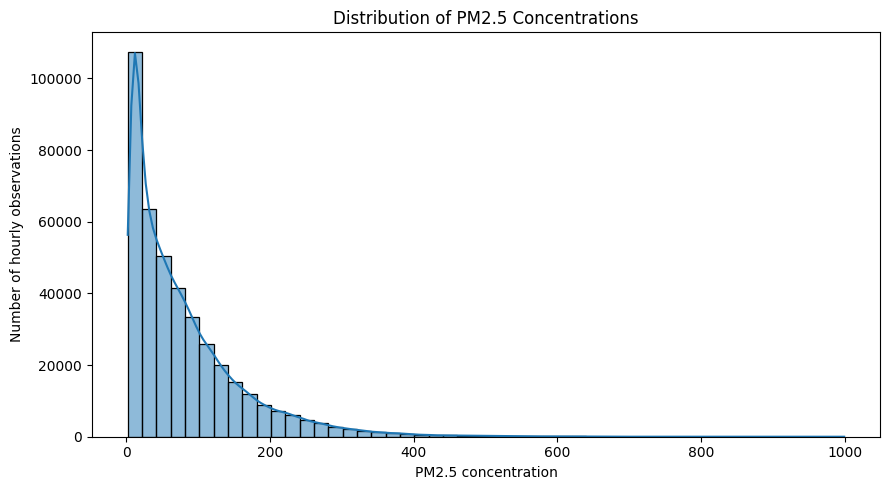

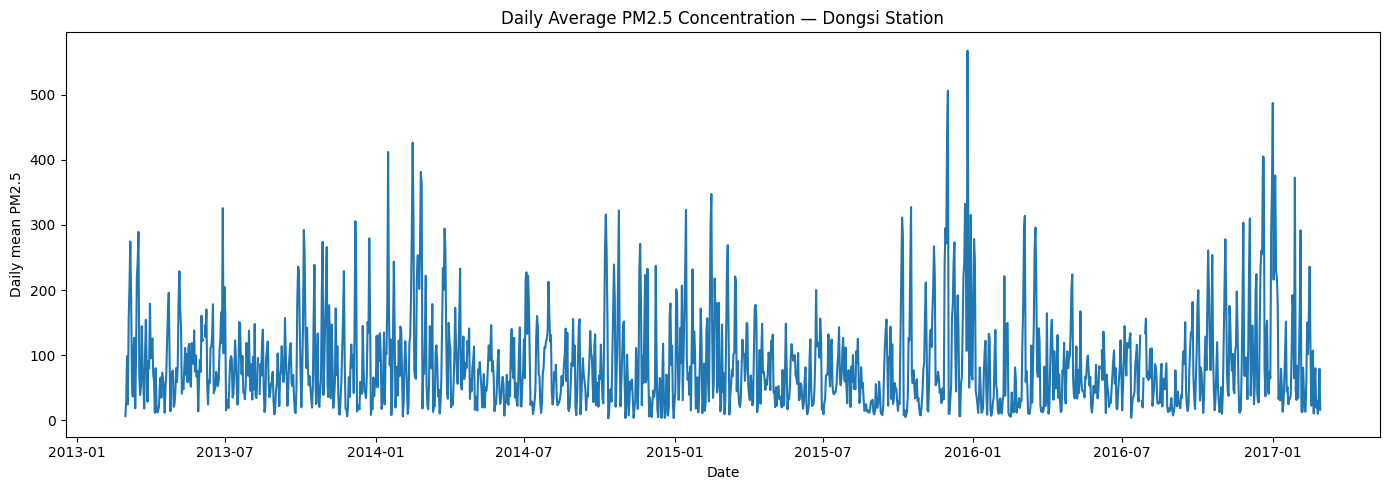

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Numerical variables to investigate
pollutants = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
weather = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

# 1. Statistical summary
print("Statistical summary of numerical variables:")
display(df[pollutants + weather].describe().T.round(2))

# 2. Missing PM2.5 values by station
print("\nMissing PM2.5 readings by station:")
display(
    df.groupby("station")["PM2.5"]
      .apply(lambda s: s.isna().sum())
      .sort_values(ascending=False)
      .rename("Missing_PM2.5")
      .to_frame()
)

# 3. PM2.5 distribution across all stations
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="PM2.5", bins=50, kde=True)
plt.title("Distribution of PM2.5 Concentrations")
plt.xlabel("PM2.5 concentration")
plt.ylabel("Number of hourly observations")
plt.tight_layout()
plt.show()

# 4. PM2.5 over time at one station
dongsi = (
    df[df["station"] == "Dongsi"]
    .sort_values("timestamp")
    .set_index("timestamp")
)

daily_pm25 = dongsi["PM2.5"].resample("D").mean()

plt.figure(figsize=(14, 5))
plt.plot(daily_pm25.index, daily_pm25)
plt.title("Daily Average PM2.5 Concentration — Dongsi Station")
plt.xlabel("Date")
plt.ylabel("Daily mean PM2.5")
plt.tight_layout()
plt.show()


In [ ]:

# PM2.5 distribution statistics
pm25 = df["PM2.5"].dropna()

print("Mean:", round(pm25.mean(), 2))
print("Median:", round(pm25.median(), 2))
print("Standard deviation:", round(pm25.std(), 2))
print("Skewness:", round(pm25.skew(), 2))
print("99th percentile:", round(pm25.quantile(0.99), 2))
print("Maximum:", round(pm25.max(), 2))

# Compare average and maximum PM2.5 by station
station_summary = df.groupby("station")["PM2.5"].agg(
    ["mean", "median", "max", "count"]
).round(2)

display(station_summary.sort_values("mean", ascending=False))


Mean: 79.79
Median: 55.0
Standard deviation: 80.82
Skewness: 2.01
99th percentile: 370.0
Maximum: 999.0


,mean,median,max,count
station,,,,
Dongsi,86.19,61.0,737.0,34314
Wanshouxigong,85.02,60.0,999.0,34368
Nongzhanguan,84.84,59.0,844.0,34436
Gucheng,83.85,60.0,770.0,34418
Wanliu,83.37,59.0,957.0,34682
Guanyuan,82.93,59.0,680.0,34448
Aotizhongxin,82.77,58.0,898.0,34139
Tiantan,82.16,59.0,821.0,34387
Shunyi,79.49,55.0,941.0,34151


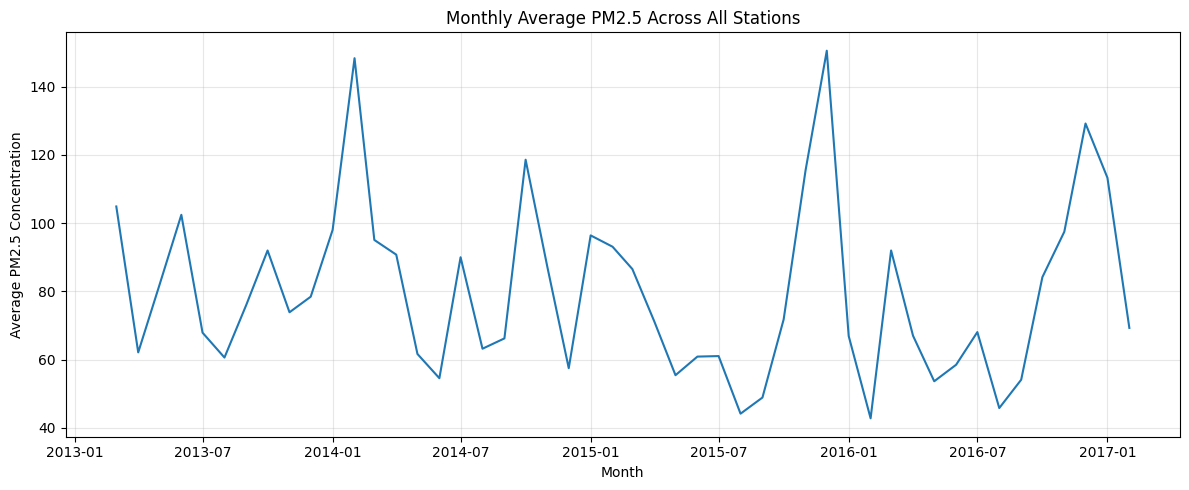

In [ ]:
# Calculate monthly average PM2.5 across all stations
monthly_pm25 = (
    df.set_index("timestamp")["PM2.5"]
    .resample("MS")
    .mean()
)

# Plot monthly trend
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(monthly_pm25.index, monthly_pm25.values)
plt.title("Monthly Average PM2.5 Across All Stations")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 Concentration")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Monthly average PM2.5 across all stations
monthly_pm25 = (
    df.set_index("timestamp")["PM2.5"]
    .resample("MS")
    .mean()
)

print("Lowest monthly average:")
print(monthly_pm25.idxmin(), round(monthly_pm25.min(), 2))

print("\nHighest monthly average:")
print(monthly_pm25.idxmax(), round(monthly_pm25.max(), 2))

print("\nFirst 12 monthly averages:")
print(monthly_pm25.head(12).round(2).to_string())

print("\nLast 12 monthly averages:")
print(monthly_pm25.tail(12).round(2).to_string())

print("\nAverage PM2.5 by calendar month:")
print(monthly_pm25.groupby(monthly_pm25.index.month).mean().round(2).to_string())

Lowest monthly average:
2016-02-01 00:00:00 42.82

Highest monthly average:
2015-12-01 00:00:00 150.52

First 12 monthly averages:
timestamp
2013-03-01    104.89
2013-04-01     62.14
2013-05-01     81.85
2013-06-01    102.44
2013-07-01     67.91
2013-08-01     60.63
2013-09-01     76.12
2013-10-01     91.99
2013-11-01     73.89
2013-12-01     78.45
2014-01-01     98.02
2014-02-01    148.32
Freq: MS

Last 12 monthly averages:
timestamp
2016-03-01     92.00
2016-04-01     67.02
2016-05-01     53.68
2016-06-01     58.52
2016-07-01     68.09
2016-08-01     45.83
2016-09-01     54.12
2016-10-01     84.18
2016-11-01     97.48
2016-12-01    129.19
2017-01-01    113.30
2017-02-01     69.31
Freq: MS

Average PM2.5 by calendar month:
timestamp
1      93.67
2      88.38
3      94.63
4      72.79
5      63.16
6      69.11
7      71.77
8      53.46
9      61.35
10     91.64
11     93.44
12    103.92


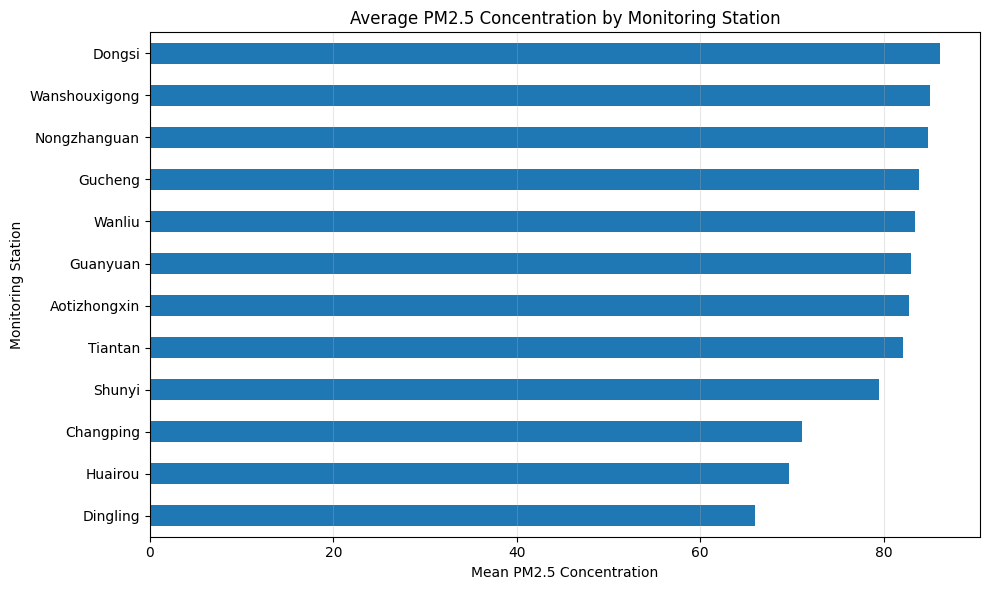

In [ ]:

import matplotlib.pyplot as plt

# Use the station_summary table we already created
station_means = station_summary["mean"].sort_values(ascending=True)

plt.figure(figsize=(10, 6))
station_means.plot(kind="barh")

plt.title("Average PM2.5 Concentration by Monitoring Station")
plt.xlabel("Mean PM2.5 Concentration")
plt.ylabel("Monitoring Station")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# Save the graph for your report
plt.savefig("pm25_by_station.png", dpi=300, bbox_inches="tight")
plt.show()


Correlation of weather variables with PM2.5:
WSPM   -0.272
TEMP   -0.131
RAIN   -0.014
PRES    0.019
DEWP    0.115
Name: PM2.5, dtype: float64


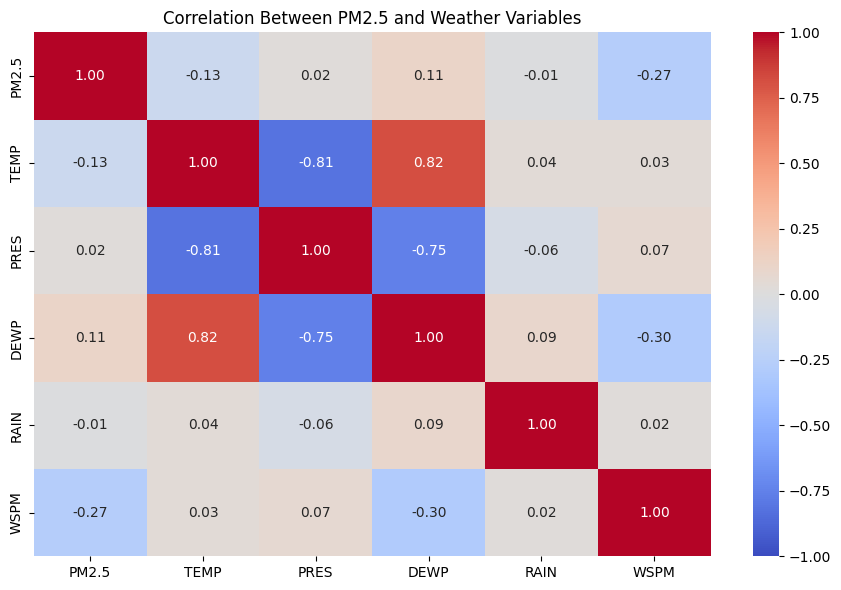

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select PM2.5 and weather variables
weather_cols = ["PM2.5", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

# Calculate pairwise Pearson correlations
correlations = df[weather_cols].corr()

# Print correlations with PM2.5
print("Correlation of weather variables with PM2.5:")
print(correlations["PM2.5"].drop("PM2.5").sort_values().round(3))

# Create and save the correlation heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(
    correlations,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Correlation Between PM2.5 and Weather Variables")
plt.tight_layout()
plt.savefig("weather_pm25_correlation.png", dpi=300, bbox_inches="tight")
plt.show()


Correlation between current PM2.5 and previous-hour PM2.5: 0.97


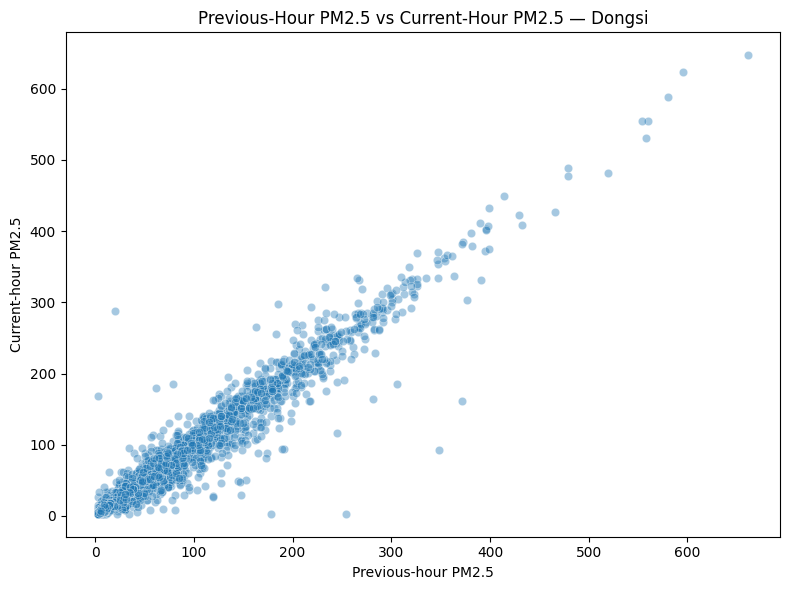

In [ ]:
# Use one station so the lag does not cross between stations
dongsi = df[df["station"] == "Dongsi"].sort_values("timestamp").copy()

# Previous hour's PM2.5 concentration
dongsi["PM2.5_lag1"] = dongsi["PM2.5"].shift(1)

# Correlation between the previous hour and current hour
lag_corr = dongsi[["PM2.5", "PM2.5_lag1"]].corr().iloc[0, 1]

print("Correlation between current PM2.5 and previous-hour PM2.5:", round(lag_corr, 3))

# Plot the relationship
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=dongsi.sample(min(3000, len(dongsi)), random_state=42),
    x="PM2.5_lag1",
    y="PM2.5",
    alpha=0.4
)
plt.title("Previous-Hour PM2.5 vs Current-Hour PM2.5 — Dongsi")
plt.xlabel("Previous-hour PM2.5")
plt.ylabel("Current-hour PM2.5")
plt.tight_layout()
plt.savefig("pm25_lag1_relationship.png", dpi=300, bbox_inches="tight")
plt.show()

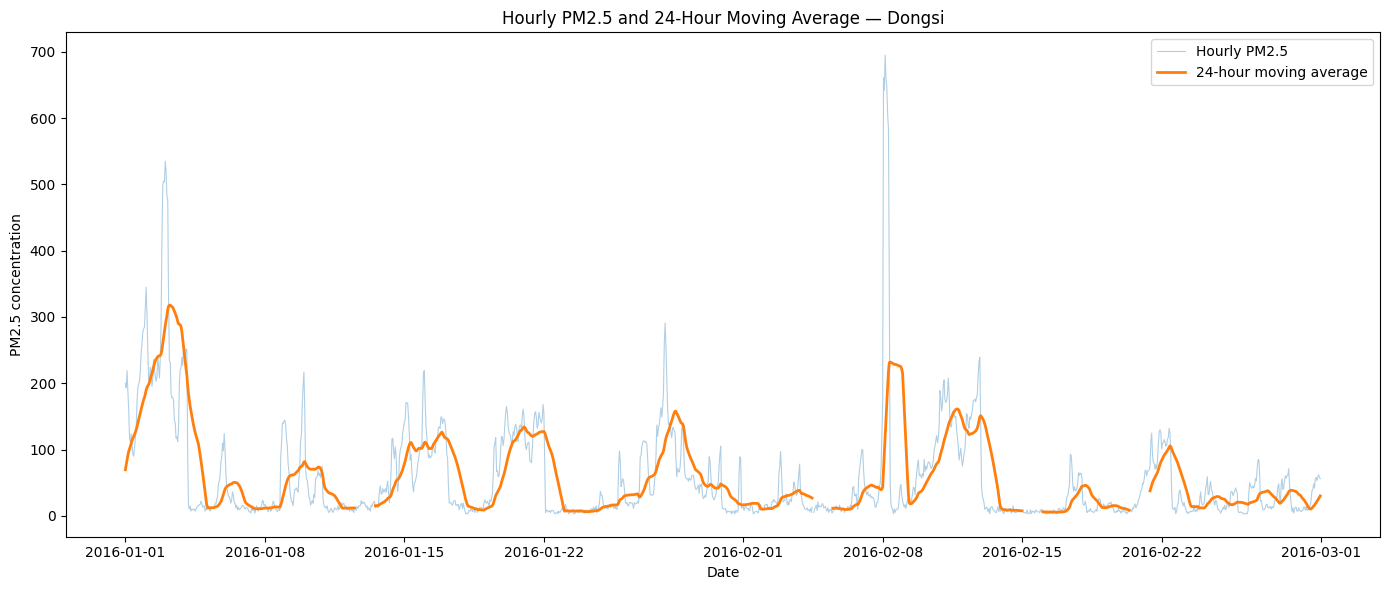

In [ ]:

# Select a two-month period so the moving average is easier to inspect
start_date = "2016-01-01"
end_date = "2016-03-01"

plot_data = dongsi[
    (dongsi["timestamp"] >= start_date) &
    (dongsi["timestamp"] < end_date)
].copy()

plt.figure(figsize=(14, 6))

plt.plot(
    plot_data["timestamp"],
    plot_data["PM2.5"],
    alpha=0.35,
    linewidth=0.8,
    label="Hourly PM2.5"
)

plt.plot(
    plot_data["timestamp"],
    plot_data["PM2.5_24h_MA"],
    linewidth=2,
    label="24-hour moving average"
)

plt.title("Hourly PM2.5 and 24-Hour Moving Average — Dongsi")
plt.xlabel("Date")
plt.ylabel("PM2.5 concentration")
plt.legend()
plt.tight_layout()
plt.savefig("pm25_24hour_moving_average.png", dpi=300, bbox_inches="tight")
plt.show()


Average PM2.5 by hour of the day:
hour
0     87.59
1     86.56
2     84.52
3     82.01
4     79.30
5     76.40
6     74.24
7     73.27
8     74.53
9     76.06
10    77.12
11    77.35
12    76.86
13    76.22
14    75.33
15    74.52
16    74.10
17    75.37
18    78.02
19    82.50
20    86.56
21    88.78
22    88.89
23    88.61
Name: PM2.5, dtype: float64


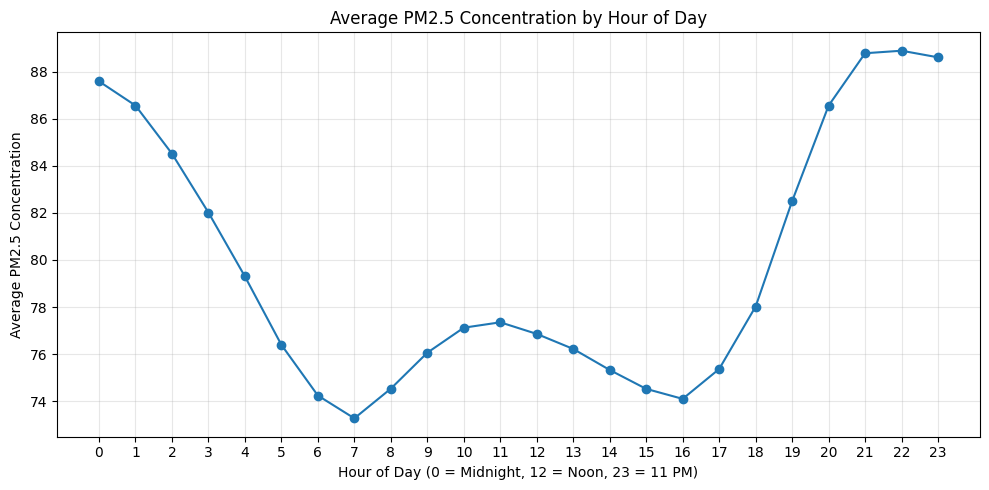

Hour with highest average: 22
Highest average: 88.89
Hour with lowest average: 7
Lowest average: 73.27


In [ ]:
# Calculate average PM2.5 for each hour across all stations
hourly_pm25 = df.groupby("hour")["PM2.5"].mean()

print("Average PM2.5 by hour of the day:")
print(hourly_pm25.round(2))

# Visualize the hourly pattern
plt.figure(figsize=(10, 5))
plt.plot(hourly_pm25.index, hourly_pm25.values, marker="o")

plt.title("Average PM2.5 Concentration by Hour of Day")
plt.xlabel("Hour of Day (0 = Midnight, 12 = Noon, 23 = 11 PM)")
plt.ylabel("Average PM2.5 Concentration")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("pm25_by_hour_of_day.png", dpi=300, bbox_inches="tight")
plt.show()

print("Hour with highest average:", hourly_pm25.idxmax())
print("Highest average:", round(hourly_pm25.max(), 2))
print("Hour with lowest average:", hourly_pm25.idxmin())
print("Lowest average:", round(hourly_pm25.min(), 2))

In [ ]:
print("Dongsi total rows:", len(dongsi))
print("Missing PM2.5 values:", dongsi["PM2.5"].isna().sum())
print("First timestamp:", dongsi["timestamp"].min())
print("Last timestamp:", dongsi["timestamp"].max())

Dongsi total rows: 35064
Missing PM2.5 values: 750
First timestamp: 2013-03-01 00:00:00
Last timestamp: 2017-02-28 23:00:00


In [ ]:

import pandas as pd
import numpy as np

# Create a clean copy of Dongsi data
model_df = (
    df[df["station"] == "Dongsi"]
    .sort_values("timestamp")
    .copy()
    .reset_index(drop=True)
)

# Predict the next hour's PM2.5
model_df["target_next_hour"] = model_df["PM2.5"].shift(-1)

# Features known at the current hour
features = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM",
    "hour", "month"
]

X = model_df[features]
y = model_df["target_next_hour"]

# Remove rows where the value we want to predict is missing
valid_target = y.notna()
X = X.loc[valid_target].copy()
y = y.loc[valid_target].copy()

print("Rows available for modelling:", len(X))
print("Number of features:", len(features))
print("Target: PM2.5 one hour ahead")
print("\nMissing feature values:")
print(X.isna().sum().sort_values(ascending=False))


Rows available for modelling: 34313
Number of features: 13
Target: PM2.5 one hour ahead

Missing feature values:
CO       2840
NO2      1236
SO2       312
O3        307
PM2.5     214
PM10      172
TEMP       20
PRES       20
DEWP       20
RAIN       20
WSPM       14
hour        0
month       0
dtype: int64


In [ ]:

split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", model_df.loc[X_train.index.min(), "timestamp"],
      "to", model_df.loc[X_train.index.max(), "timestamp"])
print("Testing period:", model_df.loc[X_test.index.min(), "timestamp"],
      "to", model_df.loc[X_test.index.max(), "timestamp"])


Training rows: 27450
Testing rows: 6863
Training period: 2013-03-01 00:00:00 to 2016-05-05 16:00:00
Testing period: 2016-05-05 17:00:00 to 2017-02-28 22:00:00


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Build a pipeline: fill missing values, then train the model
rf_baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

# Train using the training period only
rf_baseline.fit(X_train, y_train)

# Predict PM2.5 for the test period
pred_baseline = rf_baseline.predict(X_test)

# Evaluate performance
mae_baseline = mean_absolute_error(y_test, pred_baseline)
rmse_baseline = np.sqrt(mean_squared_error(y_test, pred_baseline))
r2_baseline = r2_score(y_test, pred_baseline)

print("EXPERIMENT 1: Random Forest Baseline")
print("------------------------------------")
print(f"MAE:  {mae_baseline:.3f}")
print(f"RMSE: {rmse_baseline:.3f}")
print(f"R²:   {r2_baseline:.3f}")


EXPERIMENT 1: Random Forest Baseline
------------------------------------
MAE:  11.558
RMSE: 22.164
R²:   0.942


In [ ]:

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

# Use a smaller training sample for tuning to keep the search manageable
# The final model will still be evaluated on the untouched test set.
tune_size = min(12000, len(X_train))
X_tune = X_train.iloc[:tune_size]
y_tune = y_train.iloc[:tune_size]

tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

param_grid = {
    "model__n_estimators": [50, 100, 150],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [1, 2, 5]
}

search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_grid,
    n_iter=6,
    scoring="neg_mean_absolute_error",
    cv=TimeSeriesSplit(n_splits=3),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_tune, y_tune)

print("Best parameters:", search.best_params_)
print("Best cross-validation MAE:", -search.best_score_)


Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'model__n_estimators': 150, 'model__min_samples_leaf': 5, 'model__max_depth': 10}
Best cross-validation MAE: 13.550862773729364


In [ ]:

best_rf = search.best_estimator_

# Refit the selected pipeline on all training data
best_rf.fit(X_train, y_train)

pred_tuned = best_rf.predict(X_test)

mae_tuned = mean_absolute_error(y_test, pred_tuned)
rmse_tuned = np.sqrt(mean_squared_error(y_test, pred_tuned))
r2_tuned = r2_score(y_test, pred_tuned)

results = pd.DataFrame({
    "Experiment": ["Random Forest baseline", "Tuned Random Forest"],
    "MAE": [mae_baseline, mae_tuned],
    "RMSE": [rmse_baseline, rmse_tuned],
    "R2": [r2_baseline, r2_tuned]
})

print(results.round(3).to_string(index=False))


            Experiment    MAE   RMSE    R2
Random Forest baseline 11.558 22.164 0.942
   Tuned Random Forest 11.146 21.615 0.945


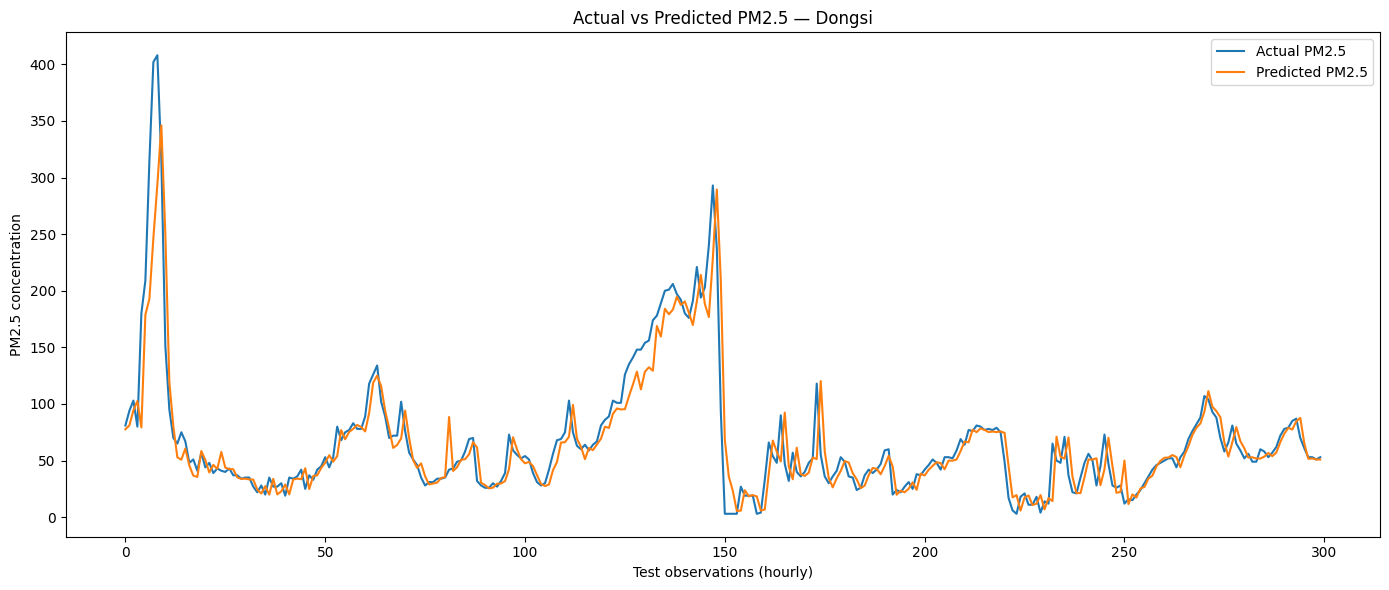

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Show a sample of 300 consecutive test observations
sample_size = 300

plt.plot(
    y_test.iloc[:sample_size].to_numpy(),
    label="Actual PM2.5",
    linewidth=1.5
)

plt.plot(
    pred_tuned[:sample_size],
    label="Predicted PM2.5",
    linewidth=1.5
)

plt.title("Actual vs Predicted PM2.5 — Dongsi")
plt.xlabel("Test observations (hourly)")
plt.ylabel("PM2.5 concentration")
plt.legend()
plt.tight_layout()

plt.savefig("actual_vs_predicted_pm25.png", dpi=300, bbox_inches="tight")
plt.show()


Feature importance ranking:
Feature  Importance
  PM2.5      0.9770
   PM10      0.0048
   WSPM      0.0044
   DEWP      0.0028
    NO2      0.0017
   hour      0.0016
    SO2      0.0016
   TEMP      0.0013
     CO      0.0013
   PRES      0.0013
     O3      0.0010
  month      0.0008
   RAIN      0.0004


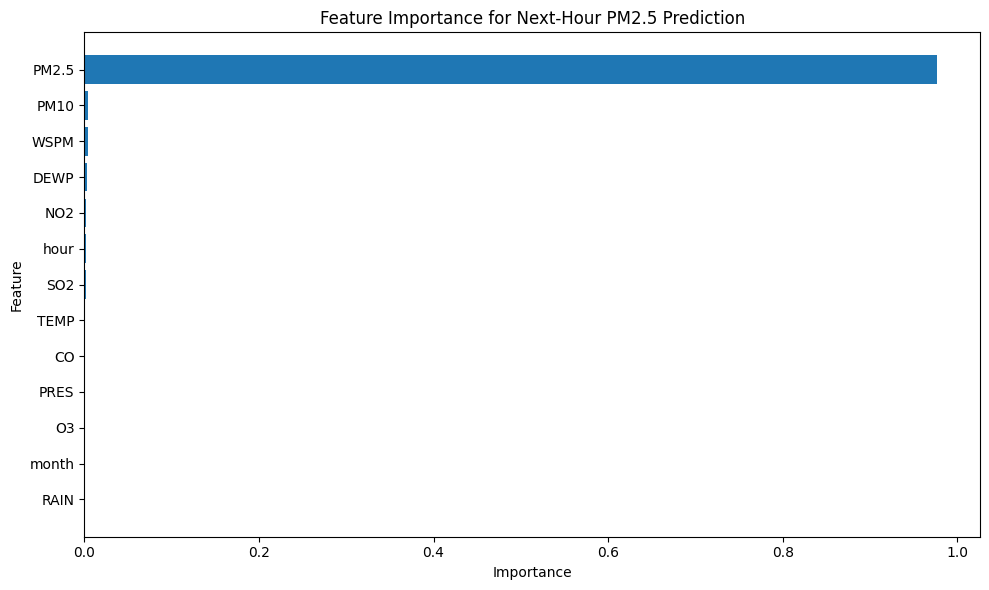

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from the trained tuned model
importance = best_rf.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": importance
}).sort_values("Importance", ascending=False)

print("Feature importance ranking:")
print(feature_importance.round(4).to_string(index=False))

# Plot the results
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)
plt.title("Feature Importance for Next-Hour PM2.5 Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("pm25_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


### Interpretation of Feature Importance

The feature importance analysis shows that the current PM2.5 concentration is the dominant predictor of PM2.5 one hour ahead, accounting for 97.70% of the model's total feature importance. PM10 and wind speed (WSPM) contribute much smaller proportions, at 0.48% and 0.44%, respectively. The remaining variables, including temperature, pressure, rainfall, and other pollutants, have relatively low importance in this model.

The dominance of current PM2.5 is consistent with the strong positive correlation of 0.97 observed between consecutive hourly PM2.5 measurements. This suggests that short-term pollution levels exhibit substantial persistence. However, feature importance reflects how the trained model uses the available predictors; it does not establish causal relationships. The results should also be interpreted in the context of the one-hour prediction horizon and the Dongsi monitoring station.


In [ ]:

results = pd.DataFrame({
    "Experiment": [
        "Experiment 1: Random Forest baseline",
        "Experiment 2: Tuned Random Forest"
    ],
    "MAE": [mae_baseline, mae_tuned],
    "RMSE": [rmse_baseline, rmse_tuned],
    "R2": [r2_baseline, r2_tuned]
})

print(results.round(3).to_string(index=False))

results.to_csv("pm25_model_comparison.csv", index=False)
print("\nModel comparison saved to pm25_model_comparison.csv")


                          Experiment    MAE   RMSE    R2
Experiment 1: Random Forest baseline 11.558 22.164 0.942
   Experiment 2: Tuned Random Forest 11.146 21.615 0.945

Model comparison saved to pm25_model_comparison.csv


,Feature,Importance
0,PM2.5,0.9770
1,PM10,0.0048
10,WSPM,0.0044
8,DEWP,0.0028
3,NO2,0.0017
11,hour,0.0016
2,SO2,0.0016
6,TEMP,0.0013
4,CO,0.0013
7,PRES,0.0013


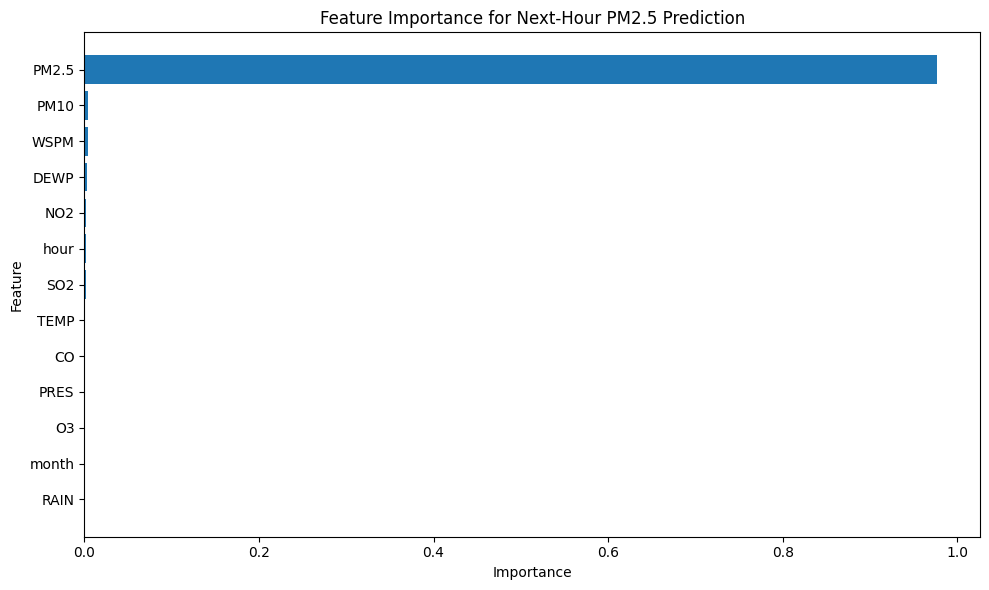

In [ ]:

importance = best_rf.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(feature_importance.round(4))

plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)
plt.title("Feature Importance for Next-Hour PM2.5 Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("pm25_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


## Conclusion

This analysis explored hourly air-quality measurements from 12 monitoring stations in Beijing between March 2013 and February 2017. The exploratory analysis examined missing values, pollutant distributions, differences in average PM2.5 concentrations between stations, monthly and hourly patterns, relationships with weather variables, lagged relationships, and moving averages.

A Random Forest regression model was developed to predict PM2.5 concentration one hour ahead at the Dongsi station. The baseline model achieved an MAE of 11.558, an RMSE of 22.164, and an R² score of 0.942. After hyperparameter tuning, the model achieved an MAE of 11.146, an RMSE of 21.615, and an R² score of 0.945. This represents a modest improvement in predictive performance.

Feature importance analysis indicated that the current PM2.5 concentration was the most influential predictor. This is consistent with the strong correlation between consecutive hourly measurements. However, the model still makes prediction errors, and its performance at other stations has not been evaluated in this experiment.

Overall, the analysis demonstrates how time-series exploration and regression modelling can be used to investigate air-quality patterns and forecast short-term PM2.5 concentrations. Future work could compare additional forecasting methods and evaluate the model at other monitoring stations.
